<a href="https://colab.research.google.com/github/leejsya/MLProgramming/blob/main/week9/DL_FashionMNIST_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### Library & Module Import

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

import numpy as np

#### Device

In [ ]:
# device 설정
device = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)
print(device)

mps


#### Transforms

In [ ]:
# preprocessing for train
transforms_train = v2.Compose(
    [
    # 이미지를 텐서로 변환
    v2.ToImage(),
    # 이미지 좌우반전 - 확률 기본값=0.5
    v2.RandomHorizontalFlip(),
    # 이미지 일부분 잘라내기 - 잘라낸 후 28크기로 resize
    v2.RandomResizedCrop(size=28, scale=(0.8, 1.0)),
    # 이미지 회전 - 최대 10도만큼
    v2.RandomRotation(degrees=10),
    # 픽셀값 데이터형 변환 및 스케일링 - float32, 0과 1 사이의 값으로 스케일링
    v2.ToDtype(dtype=torch.float32, scale=True),
    # Noramlize - 기존의 평균과 표준편차를 기준으로 각각 0과 1로 변환
    v2.Normalize(mean=[0.2863], std=[0.3532]),
    ]
)

# preprocessing for eval
transforms_eval = v2.Compose(
    [
    v2.ToImage(),
    v2.ToDtype(dtype=torch.float32, scale=True),
    v2.Normalize(mean=[0.2863], std=[0.3532]),
    ]
)

#### Dataset

In [ ]:
seed = 42

''' Train Dataset '''
train_dataset = datasets.FashionMNIST(
    root='./Data',
    train=True,
    download=True,
    transform=transforms_train
)

''' Validation Dataset '''
val_dataset = datasets.FashionMNIST(
    root='./Data',
    train=True,
    download=True,
    transform=transforms_eval
)

''' Test Dataset '''
test_dataset = datasets.FashionMNIST(
    root='./Data',
    train=False,
    download=True,
    transform=transforms_eval
)

In [ ]:
''' stratum 비율을 유지하도록 인덱스를 분할 '''
train_indices, val_indices = train_test_split(
    range(len(train_dataset)),
    # 50000 : 10000 : 10000
    test_size=1/6,
    stratify=train_dataset.targets,
    random_state=seed
)

train_dataset = Subset(train_dataset, train_indices)
val_dataset = Subset(val_dataset, val_indices)

#### DataLoader

In [ ]:
torch.manual_seed(seed)

train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=128,
    shuffle=True,
    drop_last=True
)
val_dataloader = DataLoader(
    dataset=val_dataset,
    batch_size=128,
)
test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=128,
)

#### Model

In [ ]:
from torchvision.models import resnet18
from torchinfo import summary

# torchvision에서 제공하는 resnet18 모델 사용
model = resnet18(weights=None, num_classes=10)
summary(model, input_size=(1, 3, 224, 224))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 10]                   --
├─Conv2d: 1-1                            [1, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         128
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 64, 56, 56]           --
│    └─BasicBlock: 2-1                   [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-1                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-2             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-3                    [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-4                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-5             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-6                    [1, 64, 56, 56]           --
│

In [ ]:
''' conv1 layer 세팅 변경 '''
# 채널 : 3채널 -> 1채널
# 커널사이즈 : 7 -> 3
# stride : 2 -> 1
# padding : 4 -> 1
model.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
summary(model, input_size=(1, 1, 28, 28))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 10]                   --
├─Conv2d: 1-1                            [1, 64, 28, 28]           576
├─BatchNorm2d: 1-2                       [1, 64, 28, 28]           128
├─ReLU: 1-3                              [1, 64, 28, 28]           --
├─MaxPool2d: 1-4                         [1, 64, 14, 14]           --
├─Sequential: 1-5                        [1, 64, 14, 14]           --
│    └─BasicBlock: 2-1                   [1, 64, 14, 14]           --
│    │    └─Conv2d: 3-1                  [1, 64, 14, 14]           36,864
│    │    └─BatchNorm2d: 3-2             [1, 64, 14, 14]           128
│    │    └─ReLU: 3-3                    [1, 64, 14, 14]           --
│    │    └─Conv2d: 3-4                  [1, 64, 14, 14]           36,864
│    │    └─BatchNorm2d: 3-5             [1, 64, 14, 14]           128
│    │    └─ReLU: 3-6                    [1, 64, 14, 14]           --
│  

In [ ]:
# model을 device(mps)로 이동시킴
model.to(device)
print()

#### Training Loop

In [ ]:
# Evaluation Function
def evaluate(dataloader, model, loss_fn):
    model.eval()
    losses = []
    correct, total = 0, 0
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for batch in dataloader:
            inputs, labels = batch[0].to(device), batch[1].to(device)
            preds = model(inputs)

            loss = loss_fn(preds, labels)
            losses.append(loss.item())

            # 확률이 가장 높은 클래스를 예측값으로
            pred_labels = torch.argmax(preds, dim=1)
            # 예측값과 라벨값이 같은 횟수를 더하여 저장.
            correct += (pred_labels == labels).sum().item()
            # 총 예측값 개수를 더하여 저장
            total += len(preds)

            # 각 배치의 예측값 텐서를 리스트에 저장
            all_preds.append(pred_labels.cpu())
            # 각 배치의 라벨값 텐서를 리스트에 저장
            all_labels.append(labels.cpu())

    # 각 배치의 예측값 텐서들을 행으로 이어붙임.
    all_preds = torch.cat(all_preds)
    # 각 배치의 라벨값 텐서들을 행으로 이어붙임.
    all_labels = torch.cat(all_labels)

    avg_loss = sum(losses) / len(losses)
    acc = correct / total

    return avg_loss, acc, all_preds, all_labels

In [ ]:
def Train_Loop(dataloader, model, loss_fn, optimizer, epochs, min_loss):
    step = 0
    train_loss_history = []
    train_acc_history = []
    val_loss_history = []
    val_acc_history = []

    for epoch in range(epochs):
        model.train()
        correct = 0
        total = 0
        losses = []

        for train_batch in dataloader:
            inputs, labels = train_batch[0].to(device), train_batch[1].to(device)
            preds = model(inputs)

            loss = loss_fn(preds, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            step += 1
            if step % 100 == 0:
                print(f"(step {step}) train loss: {loss.item():.4f}")

            # train loss값 저장
            losses.append(loss.item())

            # 확률이 가장 높은 클래스를 예측값으로
            pred_labels = torch.argmax(preds, dim=1)
            # 예측값과 라벨값이 같은 횟수를 더하여 저장.
            correct += (pred_labels == labels).sum().item()
            # 총 예측값 개수를 더하여 저장
            total += len(preds)

        # 평균 train loss값 추가
        train_loss_history.append(np.mean(losses))
        # 평균 train acc값 추가
        train_acc_history.append((correct/total))

        val_loss, val_acc, _, _ = evaluate(
            val_dataloader,
            model,
            loss_fn
        )
        # 평균 validation loss값 추가
        val_loss_history.append(val_loss)
        # 평균 validation acc값 추가
        val_acc_history.append(val_acc)
        print(f"[epoch {epoch+1}/{epochs}] val loss: {val_loss:.4f}, val acc: {val_acc:.4f}\n")

        # val_loss가 가장 작을 때의 모델을 저장
        if min_loss >= val_loss:
            min_loss = val_loss
            torch.save(model.state_dict(), 'State_Dict/model6.pt')

    history_dict = {
        "TLH" : train_loss_history,
        "TAH" : train_acc_history,
        "VLH" : val_loss_history,
        "VAH" : val_acc_history
    }

    print("Training Finished!")
    return min_loss, history_dict

#### Training

In [ ]:
# min_loss를 무한한 양의 실수로 초기화
min_loss = float('inf')

# loss function
loss_fn = nn.CrossEntropyLoss()
# optimizer
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# epochs=10로 모델 training
min_loss, history_dict = Train_Loop(
    train_dataloader,
    model,
    loss_fn,
    epochs=10,
    optimizer=optimizer,
    min_loss=min_loss,
)

(step 100) train loss: 0.6307
(step 200) train loss: 0.4325
(step 300) train loss: 0.4621
[epoch 1/10] val loss: 0.4279, val acc: 0.8517

(step 400) train loss: 0.3892
(step 500) train loss: 0.3106
(step 600) train loss: 0.2515
(step 700) train loss: 0.3666
[epoch 2/10] val loss: 0.2978, val acc: 0.8878

(step 800) train loss: 0.3805
(step 900) train loss: 0.4135
(step 1000) train loss: 0.2920
(step 1100) train loss: 0.2692
[epoch 3/10] val loss: 0.2778, val acc: 0.8987

(step 1200) train loss: 0.2721
(step 1300) train loss: 0.4829
(step 1400) train loss: 0.3441
(step 1500) train loss: 0.2667
[epoch 4/10] val loss: 0.2436, val acc: 0.9141

(step 1600) train loss: 0.2823
(step 1700) train loss: 0.3332
(step 1800) train loss: 0.2887
(step 1900) train loss: 0.1999
[epoch 5/10] val loss: 0.2495, val acc: 0.9084

(step 2000) train loss: 0.2488
(step 2100) train loss: 0.2012
(step 2200) train loss: 0.2350
(step 2300) train loss: 0.3492
[epoch 6/10] val loss: 0.2381, val acc: 0.9166

(step 24

#### Test

In [ ]:
# best_model 생성
best_model = resnet18(weights=None, num_classes=10)
best_model.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
best_model.to(device)
# 성능이 가장 좋았을 때의 상태를 best_model에 대입
best_model.load_state_dict(torch.load('State_Dict/model6.pt', map_location=device))
test_loss, test_acc, test_preds, test_labels = evaluate(
    dataloader=test_dataloader,
    model=best_model,
    loss_fn=loss_fn
)
print(f"test loss: {test_loss:.4f}, test acc: {test_acc:.4f}")


test loss: 0.2340, test acc: 0.9159


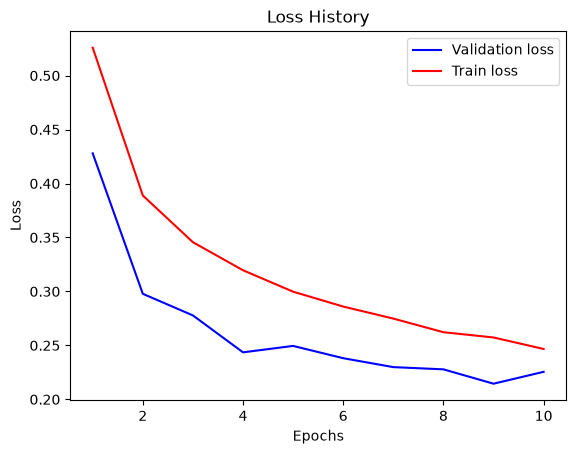

In [ ]:
import matplotlib.pyplot as plt

# 학습 중 epoch에 따라 loss의 변화를 기록하여 나타낸 그래프
plt.plot(range(1, len(history_dict["VLH"])+1), history_dict["VLH"], 'b', label="Validation loss")
plt.plot(range(1, len(history_dict["TLH"])+1), history_dict["TLH"], 'r', label="Train loss")
plt.title("Loss History")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

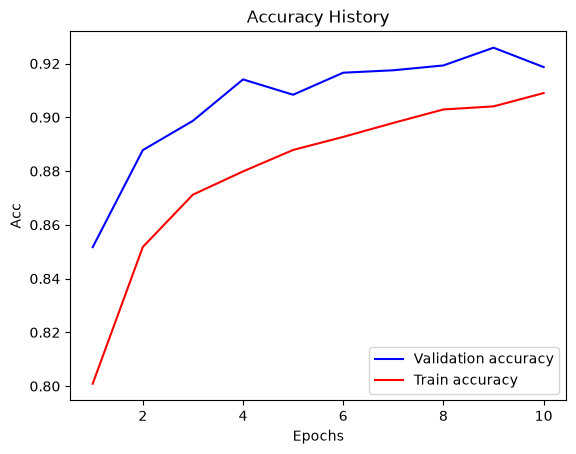

In [ ]:
# 학습 중 epoch에 따라 accuracy의 변화를 기록하여 나타낸 그래프
plt.plot(range(1, len(history_dict["VAH"])+1), history_dict["VAH"], 'b', label="Validation accuracy")
plt.plot(range(1, len(history_dict["TAH"])+1), history_dict["TAH"], 'r', label="Train accuracy")
plt.title("Accuracy History")
plt.xlabel("Epochs")
plt.ylabel("Acc")
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    test_labels, test_preds,
    output_dict=True
)
print(classification_report(test_labels, test_preds))

              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1000
           1       1.00      0.98      0.99      1000
           2       0.87      0.89      0.88      1000
           3       0.89      0.93      0.91      1000
           4       0.83      0.92      0.87      1000
           5       0.97      0.99      0.98      1000
           6       0.87      0.64      0.73      1000
           7       0.96      0.96      0.96      1000
           8       0.98      0.98      0.98      1000
           9       0.97      0.97      0.97      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.91     10000
weighted avg       0.92      0.92      0.91     10000

